### DECISION TREE -CLASSIFICATION

import libraries and load dataset

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

df = pd.read_csv("Heart_dataset")
print("Shape:", df.shape)
print("Missing values:\n", df.isna().sum())
display(df.head())
df.describe()

Shape: (918, 12)
Missing values:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Separate features from the target and train test split

In [25]:
X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Convert categorical columns into numeric columns

In [26]:
X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

Create and train the classifier

In [27]:
model = DecisionTreeClassifier(
    criterion="gini",       # Change to "entropy" for entropy/information gain
    max_depth=4,            # Limits tree depth (PRE PRUNING)
    random_state=42
)

model.fit(X_train, y_train);

Predict and evaluate

Accuracy: 0.804

Classification report:
                  precision    recall  f1-score   support

No heart disease       0.77      0.79      0.78        82
   Heart disease       0.83      0.81      0.82       102

        accuracy                           0.80       184
       macro avg       0.80      0.80      0.80       184
    weighted avg       0.80      0.80      0.80       184


Confusion matrix:
[[65 17]
 [19 83]]


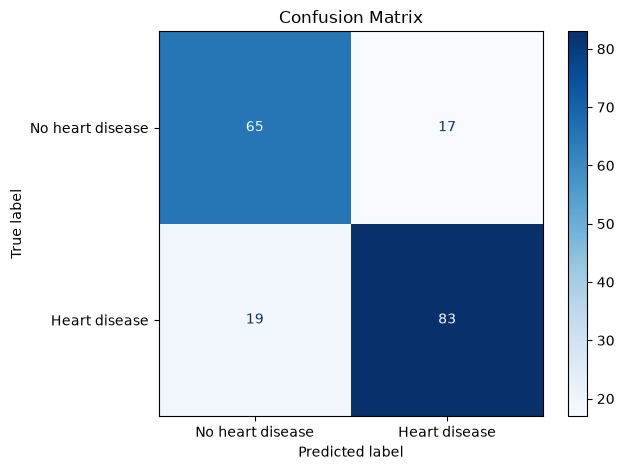

In [28]:
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["No heart disease", "Heart disease"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, predictions),
        display_labels=["No heart disease", "Heart disease"],
    ).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix")
plt.tight_layout()
plt.show()

Visualize the tree

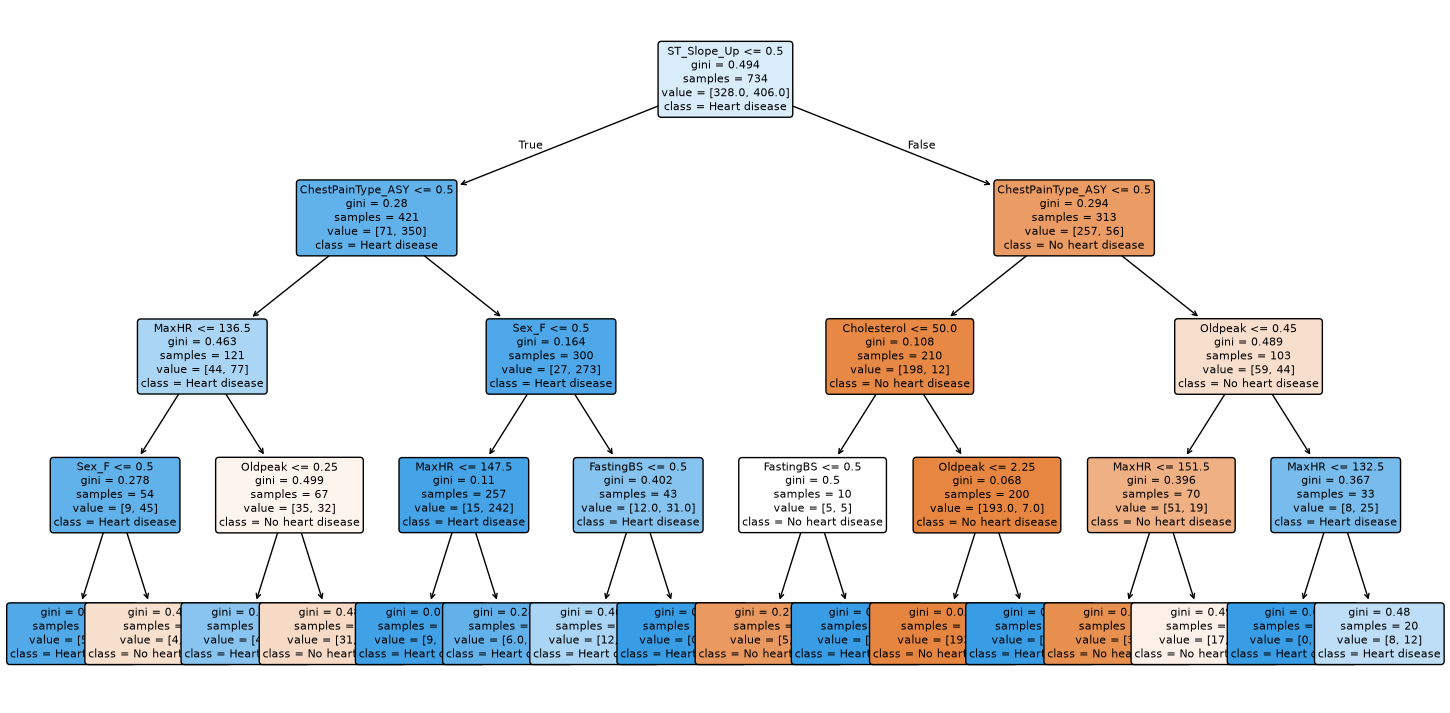

In [29]:
plt.figure(figsize=(18, 9))
plot_tree(
    model,
    feature_names=X_train.columns,
    class_names=["No heart disease", "Heart disease"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.show()

max_depth limits tree growth to help reduce overfitting. The confusion matrix shows correct and incorrect predictions; its lower-left value is the number of heart-disease cases the model missed. This is for learning purposes, not medical diagnosis.